# A2 · Co-optimising installed capacities and dispatch

In this tutorial the network of the previous tutorial is used in *greenfield* mode: there are no initial capacities, and the capacities of all generators and lines are *extendable*. The optimisation then decides at the same time the cost-optimal capacities (investment) and the hourly dispatch (operation).

The result corresponds to a long-term market equilibrium: with perfect competition, each asset recovers exactly its investment and operation costs from the market (zero profit, see Section 7). Concepts such as congestion rent for lines and scarcity peak for back-up generation are introduced.

## 0. Import the required modules

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import pypsa

pypsa.options.api.legacy_string_dtype = False  # keep pandas 3 string dtype (default from PyPSA 2.0); avoids a FutureWarning

## 1. Load the data

- `data.csv`: techno-economic parameters.
- `data_time_series.csv`: hourly capacity factors (`solar_CF`, `wind_CF`) and electricity demand (`demand_MW`).

In [2]:
### Load data.csv
params = pd.read_csv("data/data.csv", index_col="parameter")

# define a series with the values of the parameters for quick access
p = params["value"]

# show the parameters
params

,value,unit,description
parameter,,,
solar_p_nom,20.00,MW,Installed capacity of the solar PV park
solar_overnight_cost,600000.00,EUR/MW,Total (non-annualised) investment cost of sola...
solar_lifetime,25.00,years,Lifetime of solar PV
solar_marginal_cost,0.00,EUR/MWh,Operational cost of solar PV
wind_p_nom,20.00,MW,Installed capacity of the onshore wind park
wind_overnight_cost,1100000.00,EUR/MW,Total (non-annualised) investment cost of onsh...
wind_lifetime,25.00,years,Lifetime of onshore wind
wind_marginal_cost,5.00,EUR/MWh,Operational cost of onshore wind
ccgt_p_nom,50.00,MW,Installed capacity of the combined cycle gas t...


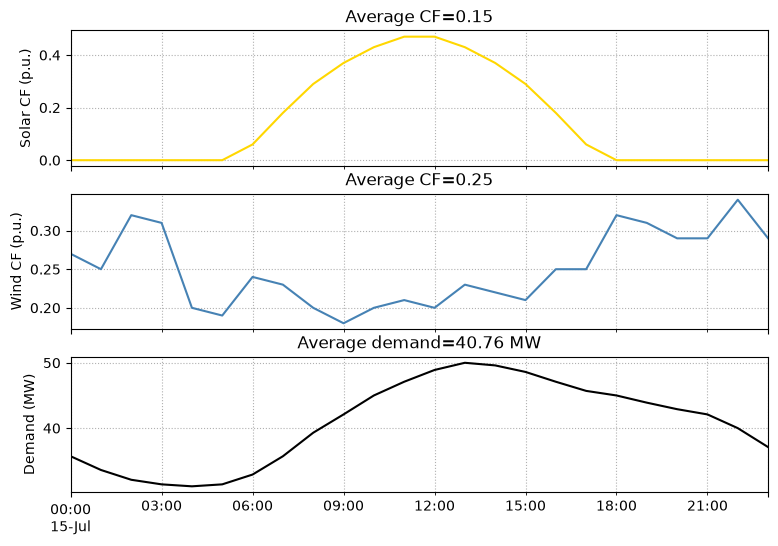

In [3]:
### Load data_time_series.csv
ts = pd.read_csv("data/data_time_series.csv", index_col="snapshot", parse_dates=True)

# Define a dict with the colors of each carrier (stored later in the network and used in all plots)
colors = {"solar": "gold",
          "wind": "steelblue",
          "gas": "indianred",
          "AC": "grey",
          "demand": "black"
}

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(9, 6), sharex=True)

ts["solar_CF"].plot(ax=ax1, color=colors["solar"], ylabel="Solar CF (p.u.)", title=f"Average CF={ts["solar_CF"].mean():.2f}").grid(ls=":", which="both")
ts["wind_CF"].plot(ax=ax2, color=colors["wind"], ylabel="Wind CF (p.u.)", title=f"Average CF={ts["wind_CF"].mean():.2f}").grid(ls=":", which="both")
ts["demand_MW"].plot(ax=ax3, color=colors["demand"], ylabel="Demand (MW)", xlabel="", title=f"Average demand={ts["demand_MW"].mean():.2f} MW").grid(ls=":", which="both")

## 2. Create the network

![Three-node network: buses, lines, generators and load](figures/network_scheme.svg)

No initial line capacity (`s_nom` = 0 by default), minimum capacity `s_nom_min=0` and `s_nom_extendable=True`.

In [4]:
n = pypsa.Network()

n.set_snapshots(ts.index)

n.add("Bus", ["North", "Center", "South"], x=[0, 0.2, 0], y=[2, 1, 0], v_nom=p["v_nom"])

n.add(
    "Line",
    ["North-Center", "South-Center"],
    bus0=["North", "South"],
    bus1=["Center", "Center"],
    x=p["line_x"],
    r=p["line_r"],
    s_nom_min=0,
    s_nom_extendable=True,
    length=p["line_length"],
    overnight_cost=p["line_overnight_cost"] * p["line_length"],
    lifetime=p["line_lifetime"],
    discount_rate=p["discount_rate"],
)

n.add("Carrier", list(colors), color=list(colors.values()))

## 3. Add generators

No initial capacity (`p_nom` = 0 by default), minimum capacity `p_nom_min=0` and `p_nom_extendable=True`.

In [5]:
### Solar PV park (South bus)
n.add(
    "Generator",
    "Solar_South",
    bus="South",
    carrier="solar",
    p_nom_min=0,
    p_nom_extendable=True,
    p_max_pu=ts["solar_CF"],
    overnight_cost=p["solar_overnight_cost"],
    lifetime=p["solar_lifetime"],
    discount_rate=p["discount_rate"],
    marginal_cost=p["solar_marginal_cost"],
)

### Wind farm (North bus)
n.add(
    "Generator",
    "Wind_North",
    bus="North",
    carrier="wind",
    p_nom_min=0,
    p_nom_extendable=True,
    p_max_pu=ts["wind_CF"],
    overnight_cost=p["wind_overnight_cost"],
    lifetime=p["wind_lifetime"],
    discount_rate=p["discount_rate"],
    marginal_cost=p["wind_marginal_cost"],
)

### Combined cycle gas turbine (Center bus)
# Dispatchable: without `p_max_pu`, it can produce up to `p_nom` in every hour.
n.add(
    "Generator",
    "CCGT_Center",
    bus="Center",
    carrier="gas",
    p_nom_min=0,
    p_nom_extendable=True,
    overnight_cost=p["ccgt_overnight_cost"],
    lifetime=p["ccgt_lifetime"],
    discount_rate=p["discount_rate"],
    marginal_cost=p["ccgt_marginal_cost"],
)

## 4. Add electricity demand

Basic parameters:

- `p_set`: imposed electricity demand (MW) in each snapshot.

In [6]:
n.add("Load",
      "Demand_Center",
      bus="Center",
      carrier="demand",
      p_set=ts["demand_MW"]
)

## 5. Optimisation

Minimises total system cost subject to the power balance at each bus and hour, the generator limits and the line capacities.

In [7]:
# io_api="direct" passes the model to HiGHS in memory; the default LP file fails silently with decimal-comma locales
# include_objective_constant=False: future default of PyPSA (avoids a FutureWarning; it does not change the results)
n.optimize(solver_name="highs", io_api="direct", include_objective_constant=False)

INFO:linopy.model: Solve problem using Highs solver


INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 125 primals, 317 duals
Objective: 5.11e+04
Solver: highs
Runtime: 0.00s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal



INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-ext-p-lower, Generator-ext-p-upper, Line-ext-s-lower, Line-ext-s-upper were not assigned to the network.


Running HiGHS 1.15.1 (git hash: n/a): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP has 317 rows; 125 cols; 569 nonzeros
Coefficient ranges:
  Matrix  [6e-02, 1e+00]
  Cost    [5e+00, 3e+02]
  Bound   [0e+00, 0e+00]
  RHS     [3e+01, 5e+01]
Presolving model
144 rows, 53 cols, 300 nonzeros 0s
Dependent equations search running on 12 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
108 rows, 53 cols, 228 nonzeros 0s
Presolve reductions: rows 108(-209); columns 53(-72); nonzeros 228(-341) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.0s
         57     5.1091399283e+04 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model status        : Optimal
Simplex   iterations: 57
Objective

('ok', 'optimal')

## 6. Results

### Summary by technology



In [8]:
cols = ["Installed Capacity", "Optimal Capacity", "Supply", "Capacity Factor", "Curtailment"] 
n.statistics(components="Generator")[cols].round(2)

,Installed Capacity,Optimal Capacity,Supply,Capacity Factor,Curtailment
gas,0.0,7.89,32.27,0.17,157.13
solar,0.0,44.20,159.13,0.15,0.00
wind,0.0,140.62,786.90,0.23,56.85


### Hourly dispatch

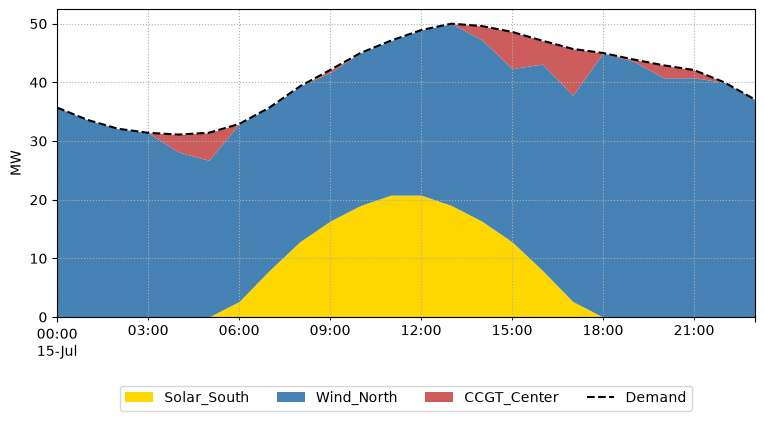

In [9]:
# Gather the dispatch of all generators
df_dispatch = n.generators_t.p

# Make a stacked area plot
ax = df_dispatch.plot.area(figsize=(9, 4), color=n.generators.carrier.map(n.carriers.color), lw=0, ylabel="MW", xlabel="")
n.loads_t.p_set["Demand_Center"].plot(ax=ax, color=n.carriers.color["demand"], ls="--", label="Demand", xlabel="")
ax.grid(ls=":", which="both")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4);

Plot with the curtailment: renewable energy that is available (`p_max_pu · p_nom_opt`) but not used.

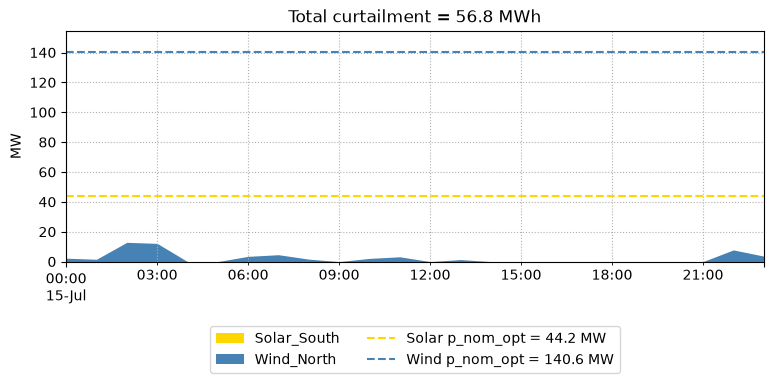

In [10]:
# Curtailment of renewables = available power - dispatched power
renewables = ["Solar_South", "Wind_North"]
p_nom_opt = n.generators.p_nom_opt
available = n.generators_t.p_max_pu[renewables] * p_nom_opt[renewables]
df_curtailment = (available - n.generators_t.p[renewables]).clip(lower=0)  # clip removes tiny negative solver round-offs

ax = df_curtailment.plot.area(figsize=(9, 3), color=n.generators.carrier[renewables].map(n.carriers.color), lw=0, ylabel="MW", xlabel="",
                              title=f"Total curtailment = {df_curtailment.sum().sum():.1f} MWh")
ax.axhline(p_nom_opt["Solar_South"], color=n.carriers.color["solar"], ls="--", lw=1.5, label=f"Solar p_nom_opt = {p_nom_opt['Solar_South']:.1f} MW")
ax.axhline(p_nom_opt["Wind_North"], color=n.carriers.color["wind"], ls="--", lw=1.5, label=f"Wind p_nom_opt = {p_nom_opt['Wind_North']:.1f} MW")
ax.set_ylim(0, 1.1 * p_nom_opt[renewables].max())
ax.grid(ls=":", which="both")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2);

### Line flows

Note that lines work at full capacity in at least one hour. Higher line capacities to avoid this would lead to unnecessary extra costs.

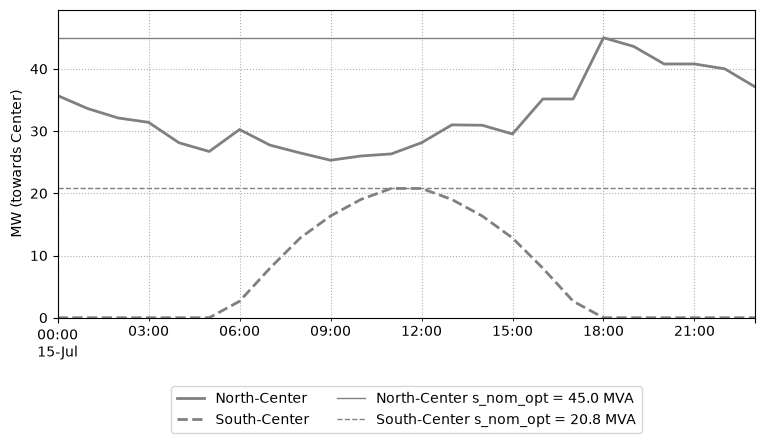

In [11]:
ac_color = n.carriers.color["AC"]
s_nom_opt = n.lines.s_nom_opt

ax = n.lines_t.p0[["North-Center", "South-Center"]].plot(figsize=(9, 4), color=ac_color, style=["-", "--"], lw=2, ylabel="MW (towards Center)", xlabel="")
ax.axhline(s_nom_opt["North-Center"], color=ac_color, ls="-", lw=1, label=f"North-Center s_nom_opt = {s_nom_opt['North-Center']:.1f} MVA")
ax.axhline(s_nom_opt["South-Center"], color=ac_color, ls="--", lw=1, label=f"South-Center s_nom_opt = {s_nom_opt['South-Center']:.1f} MVA")
ax.set_ylim(0, 1.1 * s_nom_opt.max())
ax.grid(ls=":", which="both")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2);

### Nodal prices (EUR/MWh)

Dual variable of the power balance at each bus. Unlike the previous tutorial, prices change from hour to hour:

- **5 EUR/MWh**: wind is the marginal technology (there is surplus wind, which is curtailed).
- **80 EUR/MWh**: the CCGT is the marginal technology.
- **Scarcity peak** (17:00): the CCGT runs at its full optimal capacity and the price rises well above its marginal cost (see Section 7).
- **Price separation** (12:00 and 18:00): when a line is at its full capacity, the prices at its two ends differ (South is cheaper at 12:00, North at 18:00).

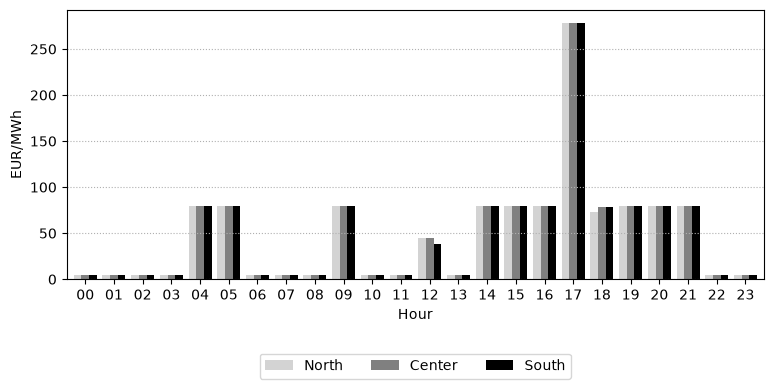

In [12]:
prices = n.buses_t.marginal_price

# Grouped bars per hour, one shade of grey per bus
ax = prices.set_axis(prices.index.strftime("%H"))[["North", "Center", "South"]].plot.bar(
    figsize=(9, 3.5), width=0.8, color=["lightgrey", "grey", "black"], ylabel="EUR/MWh", xlabel="Hour", rot=0
)
ax.grid(ls=":", axis="y")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=3);

### Cost analysis

Costs by carrier over the 24 modelled hours (EUR); lines are grouped under their carrier `AC`:

- **CAPEX**: investment annuity (from `overnight_cost`, `lifetime` and `discount_rate`) scaled to 24 h.
- **OPEX**: `marginal_cost` × dispatched energy.

In this example, lines only have CAPEX (no marginal cost).

In [13]:
cols = ["Capital Expenditure", "Operational Expenditure"]
n.statistics(components=["Generator", "Line"])[cols].round(2)

Capital Expenditure  Operational Expenditure
Generator gas                1568.11                  2581.56
          solar              6235.08                     0.00
          wind              36366.61                  3934.51
Line      AC                  405.51                     0.00

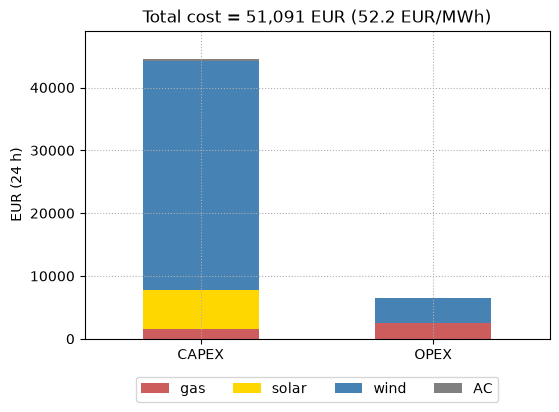

In [14]:
costs = pd.concat(
    {"CAPEX": n.statistics.capex(components=["Generator", "Line"]), "OPEX": n.statistics.opex(components=["Generator", "Line"])}, axis=1
).droplevel("component").fillna(0)

# Total cost and cost per MWh of demand
total_cost = costs.values.sum()
demand_MWh = n.loads_t.p_set.sum().sum()

ax = costs.T.plot.bar(stacked=True, figsize=(6, 4), color=costs.index.map(n.carriers.color), ylabel="EUR (24 h)", xlabel="", rot=0,
                      title=f"Total cost = {total_cost:,.0f} EUR ({total_cost / demand_MWh:.1f} EUR/MWh)")
ax.set_ylim(top=1.1 * costs.sum().max())
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4)
ax.grid(ls=":", which="both")


## 7. Economic analysis

### Investment recovery: scarcity price and congestion rent

**CCGT and the scarcity peak** (17:00). The price rises above the CCGT marginal cost by exactly its investment cost per MW for the modelled day:

- Overnight cost 900,000 EUR/MW → annuity (7 %, 30 years): 900,000 × 0.0806 ≈ 72,528 EUR/MW per year.
- Share of the 24 modelled hours: 72,528 × 24 / 8760 ≈ 198.7 EUR per MW installed.
- The CCGT recovers this amount in a single hour: 198.7 EUR/MW over 1 h is 198.7 EUR/MWh above its marginal cost, so the price is 80 + 198.7 = 278.7 EUR/MWh.

In every other hour the CCGT is paid only its marginal cost. With an optimal capacity of 7.89 MW, the income in that hour, 198.7 EUR/MWh × 7.89 MW × 1 h ≈ 1,568 EUR, is exactly the CCGT CAPEX for the day (see the check below).

**Lines and the congestion rent** (12:00 and 18:00). When a line is at its full capacity, the price difference between its two ends multiplied by the flow is the income of the line, which pays for its investment (see the revenue table below).

In [15]:
# Check: the CCGT income above its marginal cost equals its investment cost for the modelled day
annuity = p["discount_rate"] / (1 - (1 + p["discount_rate"]) ** -p["ccgt_lifetime"])
capex_per_MW = p["ccgt_overnight_cost"] * annuity * 24 / 8760  # EUR per MW installed, for the 24 modelled hours
p_nom_ccgt = n.generators.p_nom_opt["CCGT_Center"]

ccgt = n.generators_t.p["CCGT_Center"]
income_above_mc = ((prices["Center"] - p["ccgt_marginal_cost"]) * ccgt).sum()

print(f"CCGT investment cost, 24 h:   {capex_per_MW:.1f} EUR per MW installed")
print(f"CCGT CAPEX, 24 h:             {capex_per_MW:.1f} EUR/MW x {p_nom_ccgt:.2f} MW = {capex_per_MW * p_nom_ccgt:.0f} EUR")
print(f"CCGT income above its marginal cost, 24 h: {income_above_mc:.0f} EUR")

CCGT investment cost, 24 h:   198.7 EUR per MW installed
CCGT CAPEX, 24 h:             198.7 EUR/MW x 7.89 MW = 1568 EUR
CCGT income above its marginal cost, 24 h: 1568 EUR


### Revenue and market value

- **Revenue** (EUR): income from selling energy at the nodal price, $\sum_t \lambda_{b,t} \cdot p_t$, where $\lambda_{b,t}$ is the price at the bus. For a line it is the *congestion rent*, $\sum_t (\lambda_{\text{bus1},t} - \lambda_{\text{bus0},t}) \cdot p_{0,t}$. For the demand it is negative: it is what consumers pay for the energy they withdraw.
- **Market value** (EUR/MWh): revenue divided by the energy produced, i.e. the average price captured by each technology. For lines it is the revenue divided by the energy transported, i.e. the average congestion rent per MWh transported. For the demand it is the average price paid by consumers (negative sign).
- **Profit** (EUR): revenue − CAPEX − OPEX.

When all capacities are optimised, the optimality conditions guarantee that **revenue equals CAPEX + OPEX for every asset** (zero profit). This did not hold in the previous tutorial, where capacities were fixed: renewables earned more than their costs and the CCGT did not recover its CAPEX.

The revenues of all elements add up to zero: what consumers pay is shared between generators and lines. In equilibrium, the average price paid by consumers equals the total system cost per MWh of demand (see the title of the cost plot).

In [16]:
components = ["Generator", "Line", "Load"]
revenue = n.statistics.revenue(components=components, drop_zero=False).droplevel("component")
market_value = n.statistics.market_value(components=components).droplevel("component")

# The demand has no CAPEX or OPEX, so its profit is not defined (NaN)
economics = costs.reindex(revenue.index).assign(
    Revenue=revenue,
    Profit=lambda df: (df["Revenue"] - df["CAPEX"] - df["OPEX"]).round(1) + 0,  # "+ 0" turns -0.0 into 0.0
    **{"Market value (EUR/MWh)": market_value},
)
economics.round(1)

,CAPEX,OPEX,Revenue,Profit,Market value (EUR/MWh)
carrier,,,,,
gas,1568.1,2581.6,4149.7,0.0,128.6
solar,6235.1,0.0,6235.1,0.0,39.2
wind,36366.6,3934.5,40301.1,0.0,51.2
AC,405.5,0.0,405.5,0.0,0.4
demand,NaN,NaN,-51091.4,NaN,-52.2


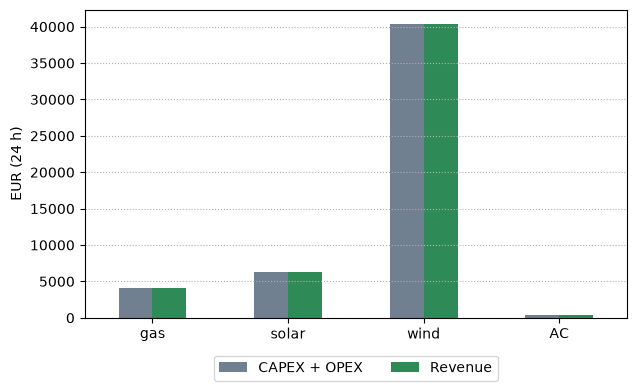

In [17]:
ax = economics.drop("demand").assign(**{"CAPEX + OPEX": costs.sum(axis=1)})[["CAPEX + OPEX", "Revenue"]].plot.bar(
    figsize=(7, 4), color=["slategrey", "seagreen"], ylabel="EUR (24 h)", xlabel="", rot=0
)
ax.grid(ls=":", axis="y")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2);

Balance between system cost and what consumers pay, by carrier: **Paid by consumers = System cost + Profit**. In equilibrium both bars are equal and there is no profit.

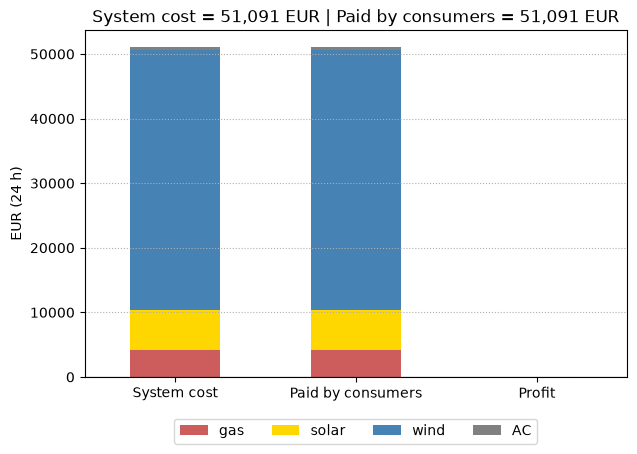

In [18]:
system_cost = costs.sum(axis=1)                  # CAPEX + OPEX of each carrier
paid = economics.drop("demand")["Revenue"]       # what consumers pay to each carrier
balance = pd.DataFrame({"System cost": system_cost, "Paid by consumers": paid, "Profit": paid - system_cost}).T

ax = balance.plot.bar(stacked=True, figsize=(7, 4.5), color=balance.columns.map(n.carriers.color), ylabel="EUR (24 h)", xlabel="", rot=0,
                      title=f"System cost = {system_cost.sum():,.0f} EUR | Paid by consumers = {paid.sum():,.0f} EUR")
ax.axhline(0, color="black", lw=0.8)
ax.grid(ls=":", axis="y")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4);

## 8. Final remarks

- Solar has the lowest cost per MWh (39.2 EUR/MWh). Why doesn't the optimisation install more solar capacity?

- Modify the notebook to impose overcapacity in a single technology (by setting its `p_nom_min` above its optimal capacity) and check the economic analysis. What happens to the profit (revenue − CAPEX − OPEX) of each technology? Who wins and who loses due to this overcapacity?

